# ML Assignment 2 — Telco Customer Churn Classification

**Student ID:** 2026aj05936 &nbsp;|&nbsp; **Course:** M.Tech (AIML) — Machine Learning

## Problem statement
A telecom operator wants to know **which customers are about to cancel their subscription (churn)** so that the retention team can contact them before they leave. Using the customer's account details, subscribed services and billing information, we build a **binary classifier** that predicts `Churn = Yes / No`.

Five classifiers are trained and compared on the same data — Logistic Regression, Decision Tree, K-Nearest Neighbours, Gaussian Naive Bayes and Support Vector Machine — using Accuracy, AUC, Precision, Recall, F1 and MCC.

**Workflow followed in this notebook**
1. Load data and check data quality (types, missing values, duplicates)
2. Exploratory Data Analysis (target balance, numeric and categorical features vs churn, correlations, outliers)
3. Pre-processing decisions derived from the EDA
4. Stratified train / test split and export of `test_data.csv` for the Streamlit app
5. Baseline models, then hyper-parameter tuning with stratified cross-validation
6. Evaluation on the held-out test set + observations
7. Saving all five fitted pipelines to `model/`

## 1. Setup
All randomness is controlled by one seed so the results in the README can be reproduced exactly. The cleaning logic lives in `churn_utils.py` and is shared with `app.py`, so that the test CSV uploaded in the app is processed identically to the training data.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from churn_utils import (
    CATEGORICAL_FEATURES, FEATURES, ID_COL, MODEL_FILES, NUMERIC_FEATURES, TARGET_COL,
    clean_features, compute_metrics, encode_target, positive_scores, predict_at_threshold,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 5936
DATA_PATH = Path("data/telco_customer_churn.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 2. Load the data
Dataset: **Telco Customer Churn** (IBM sample data, published on Kaggle: <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>).

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Reading the schema**
- 7,043 rows and 21 columns → **19 usable input features** (after removing the identifier `customerID` and the target `Churn`). This satisfies the assignment minimum of 12 features and 500 instances.
- `customerID` is a unique identifier with no predictive meaning → it will be dropped (keeping it would only let tree/KNN models memorise rows).
- `SeniorCitizen` is stored as 0/1 integers but is really a categorical Yes/No flag.
- `TotalCharges` should be numeric but is loaded as **text** — this hints at non-numeric entries, examined below.

## 3. Data quality checks

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
})
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate customerIDs:", df[ID_COL].duplicated().sum())
quality

Duplicate rows: 0 | Duplicate customerIDs: 0


,dtype,n_unique,n_missing
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


In [5]:
total_charges_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad_rows = df[total_charges_num.isna()]
print("Non-numeric TotalCharges values:", len(bad_rows), "->", bad_rows["TotalCharges"].unique())
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Non-numeric TotalCharges values: 11 -> <ArrowStringArray>
[' ']
Length: 1, dtype: str


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** pandas reports no `NaN`s, but 11 rows have a blank string `" "` in `TotalCharges`. Every one of them has `tenure = 0`, i.e. they are brand-new customers who have not received a bill yet.

**Decision:** convert `TotalCharges` to numeric and fill those 11 values with **0** (the logically correct total for a customer with zero months of tenure) instead of dropping rows or using the mean/median, which would invent charges that never happened. A `SimpleImputer(median)` is still kept in the pipeline as a safety net for unseen data. No duplicate rows or duplicate customer IDs exist, so no de-duplication is needed.

In [6]:
X_all = clean_features(df)
y_all = encode_target(df[TARGET_COL])

eda = X_all.copy()
eda["Churn"] = df[TARGET_COL].values
print("Missing values after cleaning:", int(X_all.isna().sum().sum()))
eda[NUMERIC_FEATURES].describe().T

Missing values after cleaning: 0


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


## 4. Exploratory Data Analysis

### 4.1 Target distribution

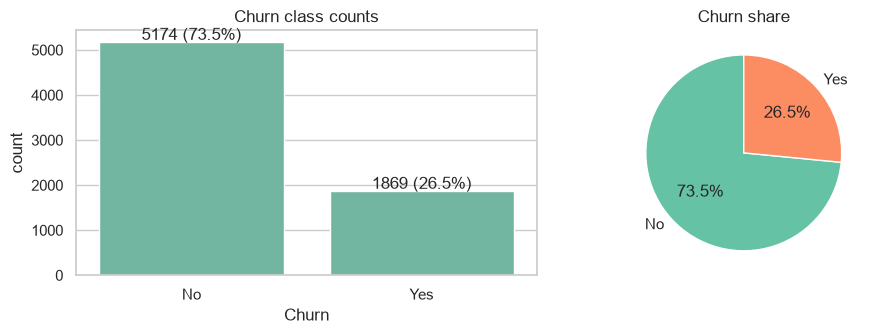

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
counts = eda["Churn"].value_counts()
sns.countplot(data=eda, x="Churn", ax=ax[0], order=["No", "Yes"])
for i, v in enumerate(counts[["No", "Yes"]]):
    ax[0].text(i, v + 50, f"{v} ({v / len(eda):.1%})", ha="center")
ax[0].set_title("Churn class counts")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Churn share")
plt.tight_layout()
plt.show()

**Observation:** only **26.5 %** of customers churn — the classes are **imbalanced (≈ 2.8 : 1)**.

**Implications for modelling**
1. A model that always predicts "No" already gets ~73 % accuracy, so **accuracy alone is misleading**. We will give more weight to **F1, MCC and AUC**, which account for the minority class.
2. The train/test split and the cross-validation folds will be **stratified** so that every split keeps the 26.5 % churn rate.
3. `class_weight="balanced"` will be offered as a hyper-parameter (for models that support it) and kept only if cross-validation shows it helps.

### 4.2 Numerical features

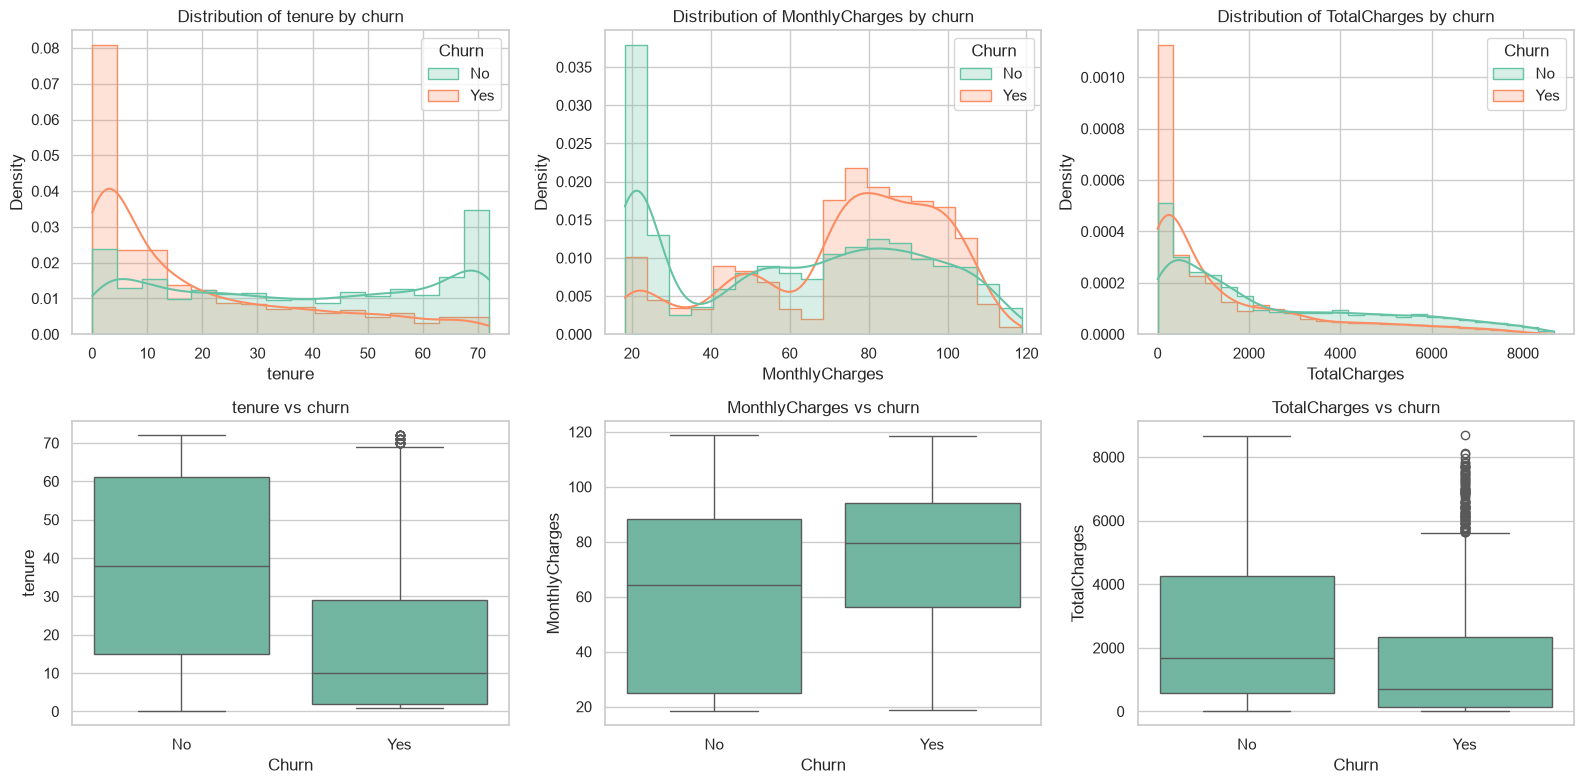

Churn,No,Yes,skew
tenure,38.000,10.00,0.239540
MonthlyCharges,64.425,79.65,-0.220524
TotalCharges,1679.525,703.55,0.963235


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(data=eda, x=col, hue="Churn", kde=True, element="step", stat="density",
                 common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {col} by churn")
    sns.boxplot(data=eda, x="Churn", y=col, ax=axes[1, i], order=["No", "Yes"])
    axes[1, i].set_title(f"{col} vs churn")
plt.tight_layout()
plt.show()

summary = eda.groupby("Churn")[NUMERIC_FEATURES].median().T
summary["skew"] = eda[NUMERIC_FEATURES].skew()
summary

**Observations**
- **tenure:** churners are concentrated in the first months (median ≈ 10 months vs ≈ 38 for loyal customers). Tenure is the strongest single numeric signal — new customers are most at risk.
- **MonthlyCharges:** churners pay more per month (median ≈ 80 vs ≈ 64). Customers on expensive plans are more likely to leave.
- **TotalCharges:** lower for churners, because it is mostly a by-product of tenure (they leave before accumulating charges). It is strongly right-skewed (skew ≈ 0.96).
- The three features are on very different scales (tenure 0–72, monthly 18–119, total 0–8,700) → **standardisation is required** for the distance/margin-based models (KNN, SVM) and helps the optimiser of Logistic Regression.

### 4.3 Outlier check (IQR rule)

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.Series({c: iqr_outliers(eda[c]) for c in NUMERIC_FEATURES}, name="IQR outliers")

tenure            0
MonthlyCharges    0
TotalCharges      0
Name: IQR outliers, dtype: int64

**Observation:** no value lies outside 1.5 × IQR for any numeric column, and all values are within plausible business ranges (tenure 0–72 months, monthly bill ≈ \$18–\$119). **No outlier treatment is needed.** The skew in `TotalCharges` is a genuine property of the data (long-tenure customers), so it is kept rather than clipped; standard scaling is sufficient for the models used here.

### 4.4 Correlation between numerical features

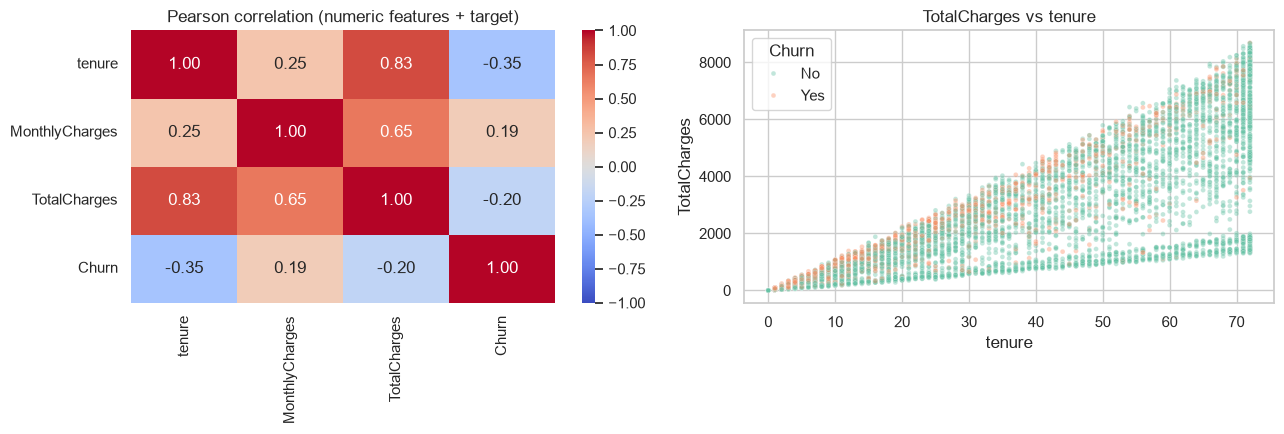

corr(TotalCharges, tenure x MonthlyCharges) = 0.9996


In [10]:
corr_df = eda[NUMERIC_FEATURES].copy()
corr_df["Churn"] = y_all
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Pearson correlation (numeric features + target)")
sns.scatterplot(data=eda, x="tenure", y="TotalCharges", hue="Churn", alpha=0.4, s=12, ax=ax[1])
ax[1].set_title("TotalCharges vs tenure")
plt.tight_layout()
plt.show()

approx = eda["tenure"] * eda["MonthlyCharges"]
print("corr(TotalCharges, tenure x MonthlyCharges) =", round(np.corrcoef(approx, eda["TotalCharges"])[0, 1], 4))

**Observations**
- `TotalCharges` is highly correlated with `tenure` (≈ 0.83) and is almost exactly `tenure × MonthlyCharges` (correlation ≈ 0.999). It therefore carries little extra information and introduces **multicollinearity**.
- Correlation with the target: `tenure` is negative (longer tenure → less churn), `MonthlyCharges` is positive, which confirms the box plots.

**Decision:** `TotalCharges` is **kept**. The models used are robust to it: Logistic Regression is L2-regularised (which stabilises correlated coefficients), and the trees, KNN and SVM do not need independent features. The small residual (TotalCharges − tenure × MonthlyCharges) reflects price changes over a customer's life, which can still be informative. The one model that assumes independent features — **Naive Bayes** — is expected to be affected, and this is discussed in the results.

### 4.5 Categorical features vs churn rate

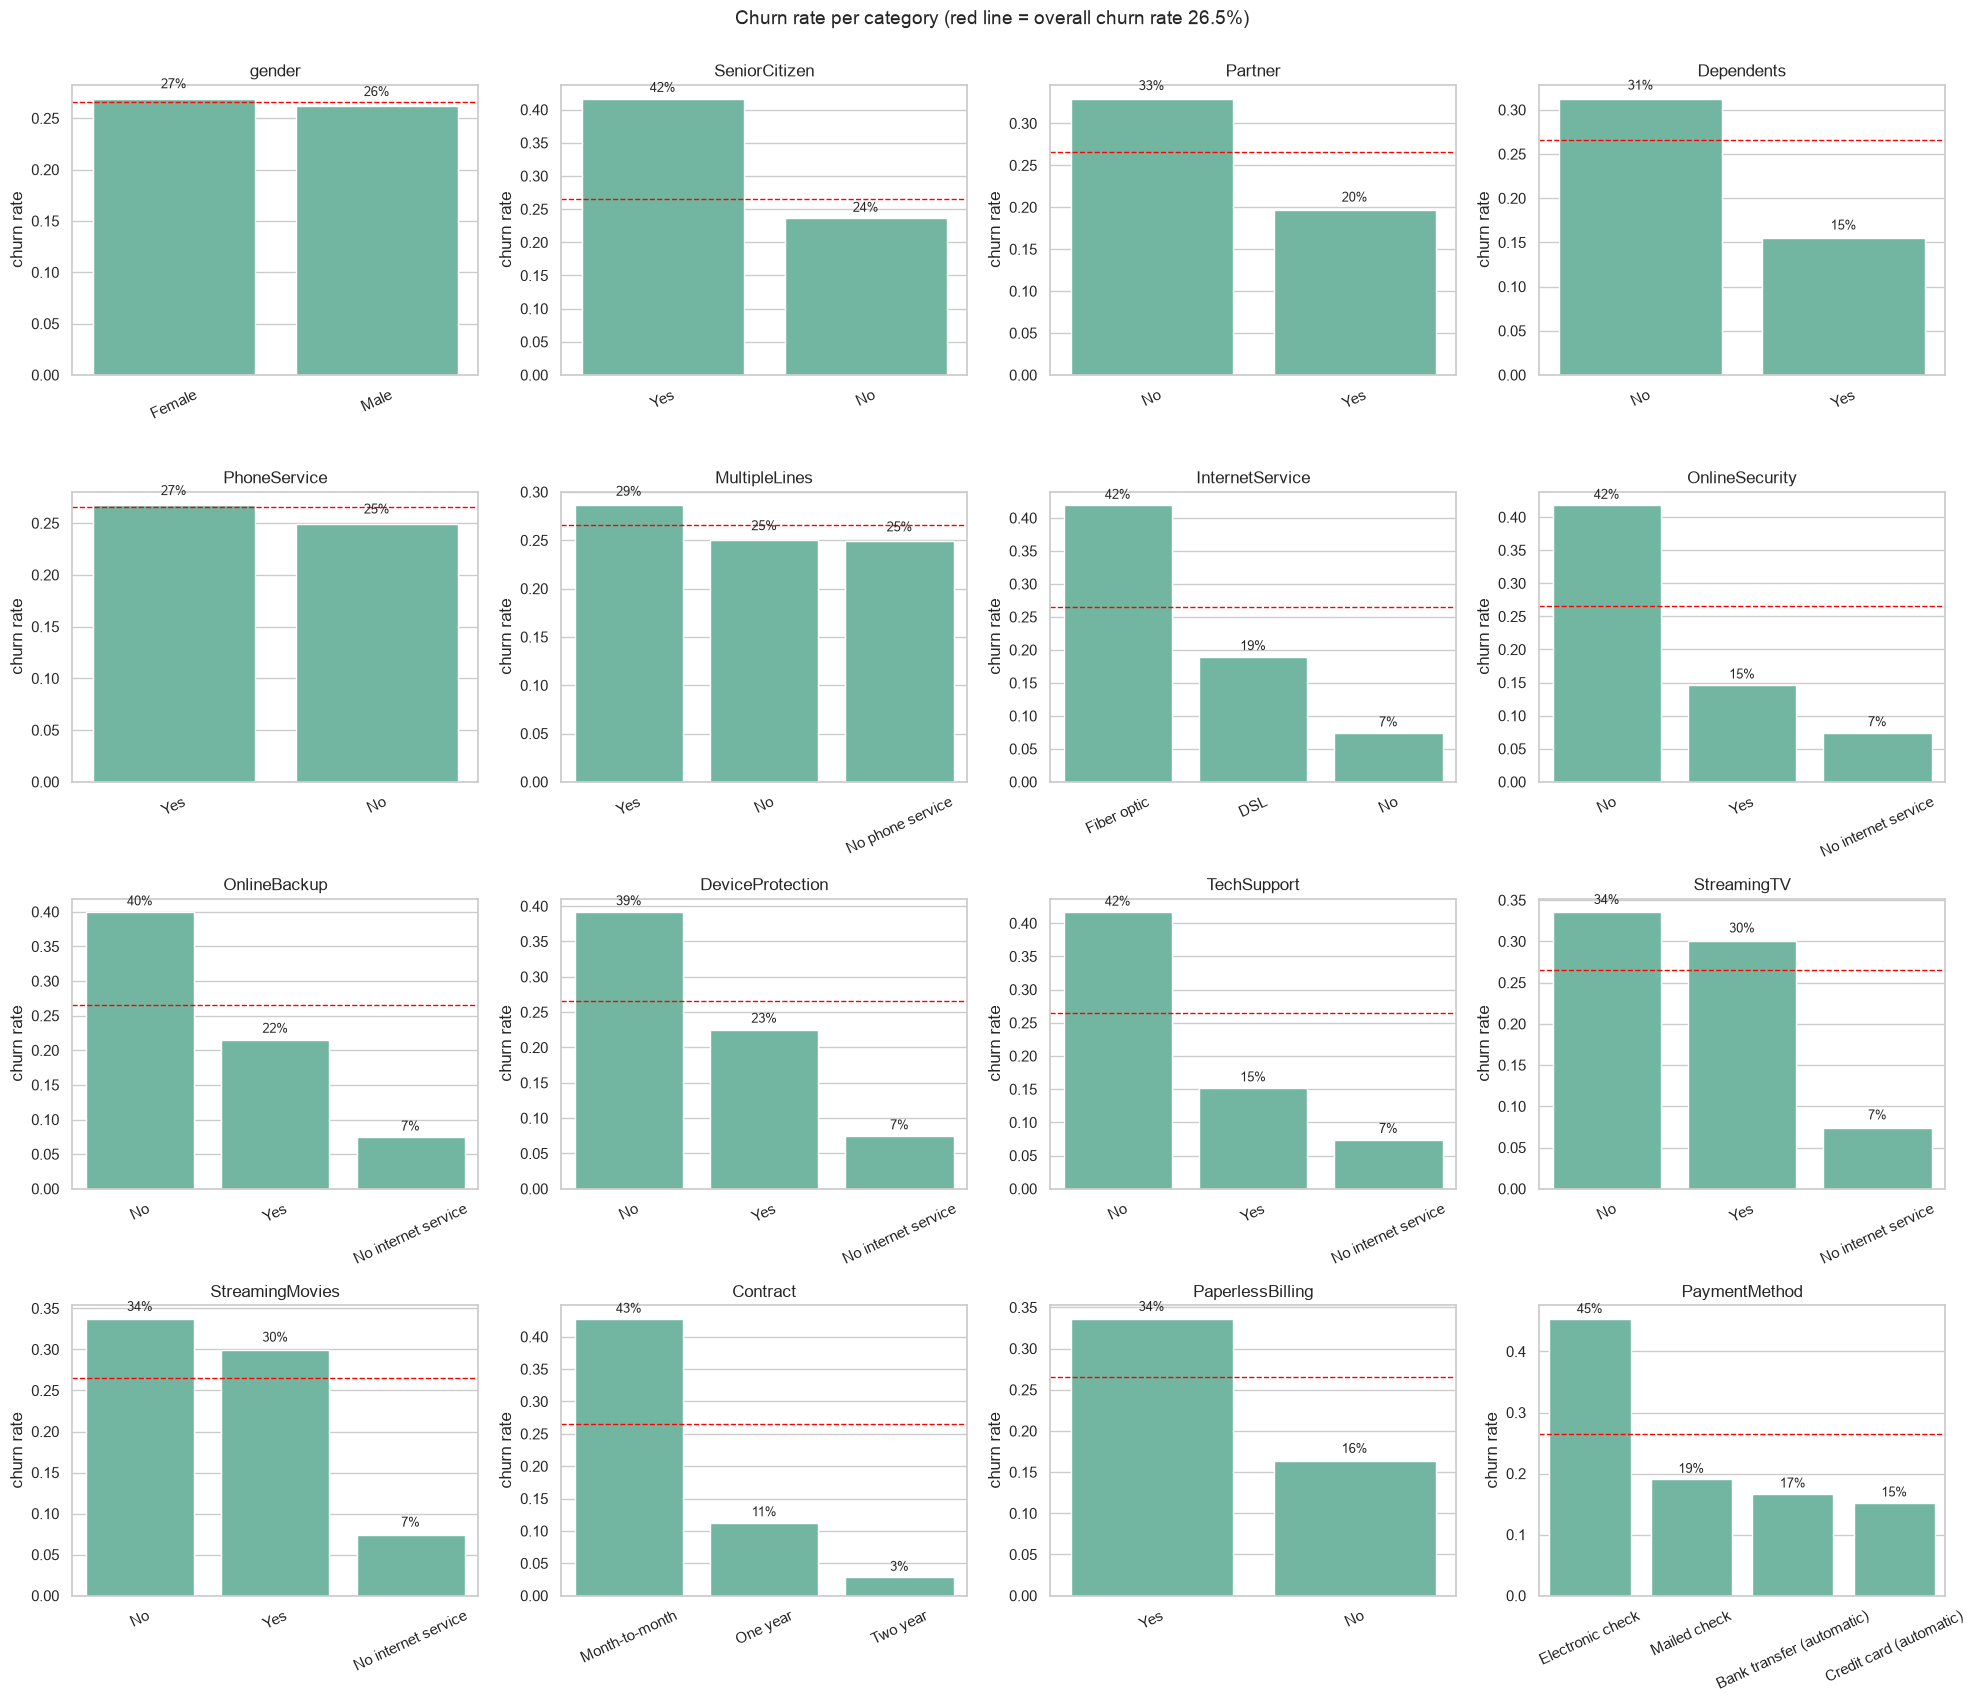

In [11]:
overall_rate = y_all.mean()
fig, axes = plt.subplots(4, 4, figsize=(20, 17))
for ax, col in zip(axes.flat, CATEGORICAL_FEATURES):
    rate = eda.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(overall_rate, ls="--", color="red", lw=1)
    ax.set_title(col)
    ax.set_ylabel("churn rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
plt.suptitle("Churn rate per category (red line = overall churn rate 26.5%)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
rows = []
for col in CATEGORICAL_FEATURES:
    rate = eda.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())
    rows.append({"feature": col, "n_categories": eda[col].nunique(),
                 "max_rate": rate.max(), "min_rate": rate.min(), "spread": rate.max() - rate.min(),
                 "highest_risk_category": rate.idxmax()})
cat_summary = pd.DataFrame(rows).sort_values("spread", ascending=False).reset_index(drop=True)
cat_summary.style.format({"max_rate": "{:.1%}", "min_rate": "{:.1%}", "spread": "{:.1%}"})

,feature,n_categories,max_rate,min_rate,spread,highest_risk_category
0,Contract,3,42.7%,2.8%,39.9%,Month-to-month
1,InternetService,3,41.9%,7.4%,34.5%,Fiber optic
2,OnlineSecurity,3,41.8%,7.4%,34.4%,No
3,TechSupport,3,41.6%,7.4%,34.2%,No
4,OnlineBackup,3,39.9%,7.4%,32.5%,No
5,DeviceProtection,3,39.1%,7.4%,31.7%,No
6,PaymentMethod,4,45.3%,15.2%,30.0%,Electronic check
7,StreamingMovies,3,33.7%,7.4%,26.3%,No
8,StreamingTV,3,33.5%,7.4%,26.1%,No
9,SeniorCitizen,2,41.7%,23.6%,18.1%,Yes


**Observations (sorted by how much the churn rate varies across categories)**
- **Contract** is the most important categorical driver: month-to-month customers churn far more (≈ 43 %) than one-year (≈ 11 %) or two-year (≈ 3 %) customers.
- **InternetService:** Fiber-optic users churn the most (≈ 42 %), despite being the premium service — this is consistent with the higher `MonthlyCharges` of churners.
- **PaymentMethod:** Electronic-check payers churn at ≈ 45 %, almost 3× the automatic payment methods (≈ 15–17 %).
- **OnlineSecurity / TechSupport / OnlineBackup / DeviceProtection:** customers *without* these add-ons churn much more. Their "No internet service" category has very low churn (≈ 7 %) — these customers have only a phone line.
- **SeniorCitizen, PaperlessBilling, Partner, Dependents** show moderate effects (e.g. seniors ≈ 42 % vs ≈ 24 %).
- **gender** and **PhoneService** show almost no difference in churn rate → weak predictors.

**Decisions**
- All categorical features are **one-hot encoded** (none of them have a natural order that a numeric code would represent correctly; `Contract` is ordinal-looking, but one-hot lets every model learn its own effect for each level). `drop="if_binary"` keeps one column for Yes/No features, avoiding redundant columns.
- `gender` and `PhoneService` are weak but are **not removed**: one-hot encoding adds only one column each, regularisation/tree splitting will down-weight them, and removing features based on univariate analysis alone can miss interactions.
- The "No internet service" level is repeated across six columns (it duplicates `InternetService = No`). This redundancy is harmless for these models, so the original categories are kept to preserve interpretability.

### 4.6 Interaction: tenure × contract

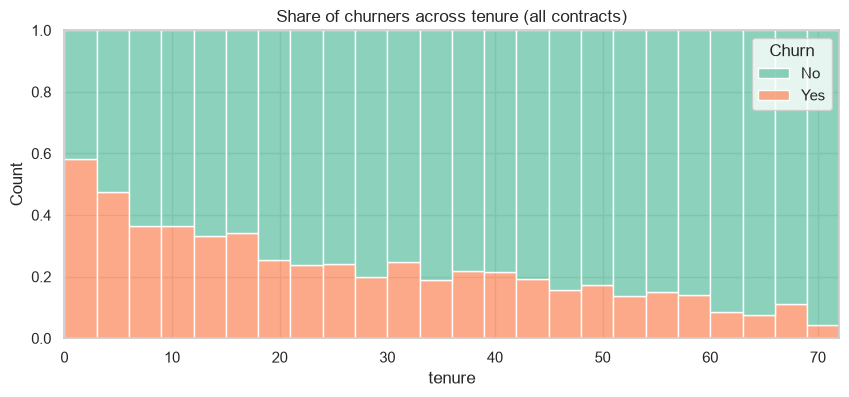

Contract,Month-to-month,One year,Two year
tenure,,,
"(-1, 6]",55%,10%,0%
"(6, 12]",42%,11%,0%
"(12, 24]",38%,8%,0%
"(24, 48]",33%,11%,2%
"(48, 72]",26%,13%,3%


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=eda, x="tenure", hue="Churn", multiple="fill", bins=24, ax=ax, hue_order=["No", "Yes"])
ax.set_title("Share of churners across tenure (all contracts)")
plt.show()

pd.crosstab(pd.cut(eda["tenure"], [-1, 6, 12, 24, 48, 72]), eda["Contract"],
            values=(eda["Churn"] == "Yes"), aggfunc="mean").style.format("{:.0%}").background_gradient(cmap="Reds")

**Observation:** churn falls steadily with tenure, but contract type changes the picture at every tenure level: a month-to-month customer in their first 6 months churns more than 50 % of the time, while two-year customers hardly churn at all. This is an **interaction effect** — the risk depends on combinations of features. Non-linear models (Decision Tree, KNN, RBF-SVM) can capture this directly, whereas Logistic Regression must approximate it additively. This is one reason to compare linear and non-linear models.

### 4.7 EDA summary → pre-processing plan
| Finding | Action |
|---|---|
| `customerID` is a unique identifier | Drop |
| `TotalCharges` is text with 11 blanks (all tenure = 0) | Convert to numeric, fill with 0 (+ median imputer as a safety net) |
| `SeniorCitizen` is a 0/1 code for a category | Treat as categorical |
| Numeric features on very different scales | `StandardScaler` (required for KNN/SVM, helps LR) |
| 16 nominal categorical features | `OneHotEncoder(drop="if_binary", handle_unknown="ignore")` |
| No outliers by IQR, no duplicates | No removal / clipping |
| 26.5 % churn (imbalanced) | Stratified split + stratified CV, F1/MCC/AUC focus, tune `class_weight` |
| `TotalCharges` ≈ `tenure × MonthlyCharges` | Keep; handled by regularisation / non-linear models |

All of this is implemented inside a scikit-learn **`Pipeline`**, so the scaler and encoder are fitted **only on the training folds** (no data leakage), and the saved model can be applied directly to the raw test CSV in the Streamlit app.

## 5. Train / test split
An 80 / 20 **stratified** split is used: 5,634 rows to train and tune, 1,409 rows held out and never seen during training or tuning. The held-out rows are saved **in their original raw format** (including `customerID` and `Churn`) as `test_data.csv`; this is the file uploaded to the Streamlit app.

In [14]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df[TARGET_COL], random_state=RANDOM_STATE)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

test_df.to_csv("test_data.csv", index=False)

X_train, y_train = clean_features(train_df), encode_target(train_df[TARGET_COL])
X_test, y_test = clean_features(test_df), encode_target(test_df[TARGET_COL])

print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape}, churn rate {y_test.mean():.3f}")

Train: (5634, 19), churn rate 0.265
Test : (1409, 19), churn rate 0.265


## 6. Pre-processing pipeline
- **Numeric** (`tenure`, `MonthlyCharges`, `TotalCharges`): median imputation (safety net) → standard scaling.
- **Categorical** (16 columns): one-hot encoding; `handle_unknown="ignore"` prevents the app from crashing if an unseen category appears in an uploaded file.

The encoder outputs a **dense** matrix (`sparse_output=False`) because Gaussian Naive Bayes does not accept sparse input; the matrix is small (≈ 40 columns) so this costs nothing.

In [15]:
def make_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([("num", numeric, NUMERIC_FEATURES), ("cat", categorical, CATEGORICAL_FEATURES)])

pre = make_preprocessor().fit(X_train)
print("Number of model input columns after encoding:", len(pre.get_feature_names_out()))
list(pre.get_feature_names_out())

Number of model input columns after encoding: 40


['num__tenure',
 'num__MonthlyCharges',
 'num__TotalCharges',
 'cat__gender_Male',
 'cat__SeniorCitizen_Yes',
 'cat__Partner_Yes',
 'cat__Dependents_Yes',
 'cat__PhoneService_Yes',
 'cat__MultipleLines_No',
 'cat__MultipleLines_No phone service',
 'cat__MultipleLines_Yes',
 'cat__InternetService_DSL',
 'cat__InternetService_Fiber optic',
 'cat__InternetService_No',
 'cat__OnlineSecurity_No',
 'cat__OnlineSecurity_No internet service',
 'cat__OnlineSecurity_Yes',
 'cat__OnlineBackup_No',
 'cat__OnlineBackup_No internet service',
 'cat__OnlineBackup_Yes',
 'cat__DeviceProtection_No',
 'cat__DeviceProtection_No internet service',
 'cat__DeviceProtection_Yes',
 'cat__TechSupport_No',
 'cat__TechSupport_No internet service',
 'cat__TechSupport_Yes',
 'cat__StreamingTV_No',
 'cat__StreamingTV_No internet service',
 'cat__StreamingTV_Yes',
 'cat__StreamingMovies_No',
 'cat__StreamingMovies_No internet service',
 'cat__StreamingMovies_Yes',
 'cat__Contract_Month-to-month',
 'cat__Contract_One 

## 7. Baselines (default hyper-parameters)
Before tuning, every model is evaluated with its default settings using **5-fold stratified cross-validation on the training set only**. A `DummyClassifier` that always predicts the majority class is included as a floor. This shows (a) how much each model learns beyond chance and (b) how much tuning later adds.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "roc_auc": "roc_auc", "precision": "precision",
           "recall": "recall", "f1": "f1", "mcc": "matthews_corrcoef"}

base_estimators = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(random_state=RANDOM_STATE),
}

rows = []
for name, est in base_estimators.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    rows.append({"Model": name, **{k: res[f"test_{k}"].mean() for k in SCORING}})
baseline_cv = pd.DataFrame(rows).set_index("Model").round(4)
baseline_cv

,accuracy,roc_auc,precision,recall,f1,mcc
Model,,,,,,
Majority-class baseline,0.7346,0.5000,0.0000,0.0000,0.0000,0.0000
Logistic Regression,0.8024,0.8443,0.6514,0.5512,0.5969,0.4703
Decision Tree,0.7307,0.6584,0.4925,0.5017,0.4969,0.3133
KNN,0.7669,0.7860,0.5654,0.5304,0.5471,0.3910
Naive Bayes,0.6899,0.8186,0.4549,0.8488,0.5923,0.4252
Support Vector Machine,0.8014,0.7965,0.6716,0.4923,0.5680,0.4521


**Observations on the baselines**
- The majority-class baseline reaches ≈ 0.73 accuracy but **F1 = 0 and MCC = 0** — it never finds a churner. This confirms why accuracy alone cannot be the selection metric.
- **Logistic Regression** is the strongest default model (best F1, MCC and AUC). The default **SVM** has similar accuracy and the highest precision, but low recall.
- The **unrestricted Decision Tree overfits** (it grows until every leaf is pure): it has the lowest AUC (≈ 0.66) of all learned models. Default KNN (k = 5) is noisy and also weak.
- Gaussian Naive Bayes achieves very high recall but low precision: it labels many customers as churners. This is a symptom of its feature-independence assumption on correlated, one-hot-encoded inputs.
- With default settings, recall for most models is only ≈ 0.5 — half the churners are missed. Tuning (including `class_weight`) should address this.

## 8. Hyper-parameter tuning (GridSearchCV, 5-fold stratified CV)
**Selection metric = F1 of the churn class.** For a retention campaign we want to catch as many churners as possible (recall) without contacting too many loyal customers (precision); F1 balances the two and, unlike accuracy, is not inflated by the majority class. MCC and AUC are also reported for every model.

Search spaces and the reasoning behind them:
- **Logistic Regression** — `C` (inverse L2 strength) to control over/under-fitting; `class_weight` to counter the imbalance.
- **Decision Tree** — `max_depth`, `min_samples_leaf` to **limit tree growth** (the baseline showed overfitting); `criterion`; `class_weight`.
- **KNN** — `n_neighbors` (larger k = smoother boundary, less variance); `weights` (uniform vs distance); `p` (Manhattan vs Euclidean). KNN has no `class_weight`.
- **Naive Bayes (Gaussian)** — `var_smoothing`, the only hyper-parameter; it adds variance to every feature for numerical stability, which matters for 0/1 one-hot columns.
- **SVM (RBF kernel)** — `C` (margin softness) and `gamma` (kernel width), plus `class_weight`. RBF is chosen over linear because the EDA showed interactions (tenure × contract). During the search `probability=False` for speed; the best configuration is then re-fitted with `probability=True` so the app can output probabilities.

In [17]:
search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "clf__min_samples_leaf": [1, 10, 25, 50, 100],
         "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31, 41, 61, 81, 101, 151, 201], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]},
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": np.logspace(-9, 1, 21)},
    ),
    "Support Vector Machine": (
        SVC(kernel="rbf", random_state=RANDOM_STATE),
        {"clf__C": [0.1, 0.3, 1, 3], "clf__gamma": ["scale", 0.01, 0.03, 0.1], "clf__class_weight": [None, "balanced"]},
    ),
}

searches = {}
for name, (est, grid) in search_spaces.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    gs = GridSearchCV(pipe, grid, scoring=SCORING, refit="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:<24} best CV F1 = {gs.best_score_:.4f}  params = "
          f"{ {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }")

Logistic Regression      best CV F1 = 0.6302  params = {'C': 0.3, 'class_weight': 'balanced'}


Decision Tree            best CV F1 = 0.6204  params = {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}


KNN                      best CV F1 = 0.6048  params = {'n_neighbors': 61, 'p': 1, 'weights': 'uniform'}


Naive Bayes              best CV F1 = 0.6075  params = {'var_smoothing': np.float64(1.0)}


Support Vector Machine   best CV F1 = 0.6225  params = {'C': 0.3, 'class_weight': 'balanced', 'gamma': 0.1}


In [18]:
def cv_row(gs):
    i = gs.best_index_
    return {k: gs.cv_results_[f"mean_test_{k}"][i] for k in SCORING}

tuned_cv = pd.DataFrame({name: cv_row(gs) for name, gs in searches.items()}).T.round(4)
comparison = pd.concat({"default": baseline_cv.drop("Majority-class baseline")[["f1", "mcc", "roc_auc"]],
                        "tuned": tuned_cv[["f1", "mcc", "roc_auc"]]}, axis=1)
comparison

default                   tuned                
                            f1     mcc roc_auc      f1     mcc roc_auc
Logistic Regression     0.5969  0.4703  0.8443  0.6302  0.4794  0.8441
Decision Tree           0.4969  0.3133  0.6584  0.6204  0.4637  0.8180
KNN                     0.5471  0.3910  0.7860  0.6048  0.4661  0.8329
Naive Bayes             0.5923  0.4252  0.8186  0.6075  0.4448  0.8259
Support Vector Machine  0.5680  0.4521  0.7965  0.6225  0.4671  0.8297

**Effect of tuning (cross-validated, training data only):** tuning improves F1 for every model. The largest gains are for the **Decision Tree** (limiting depth/leaf size removes overfitting) and **KNN** (larger k smooths the boundary). Where `class_weight="balanced"` was selected, the model trades some precision for much higher recall, which is what the F1 objective favours on an imbalanced target.

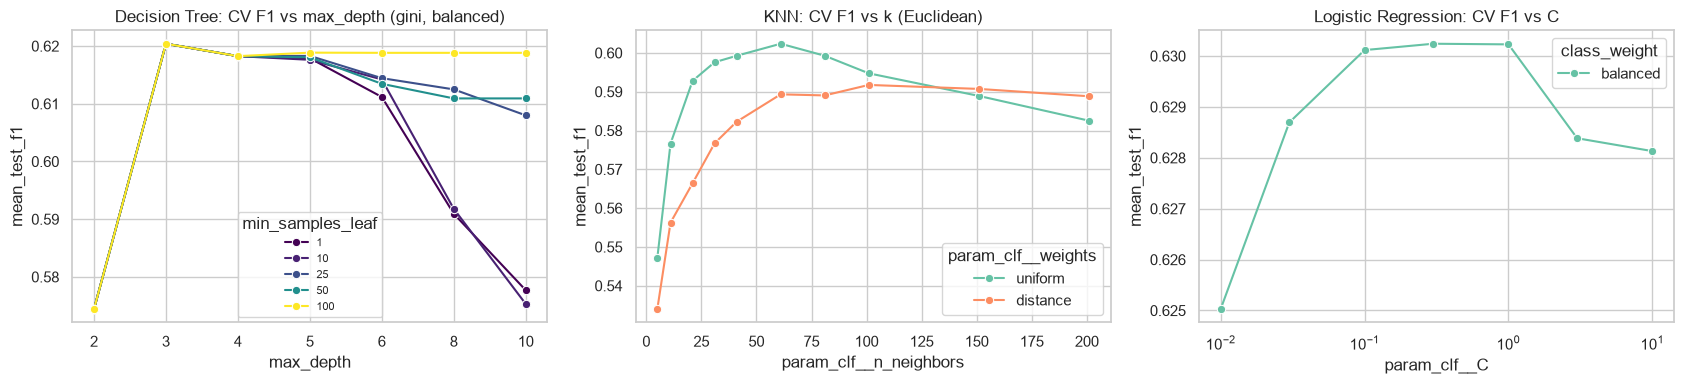

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

dt = pd.DataFrame(searches["Decision Tree"].cv_results_)
dt = dt[(dt.param_clf__criterion == "gini") & (dt.param_clf__class_weight == "balanced")]
dt["max_depth"] = dt.param_clf__max_depth.astype(str)
sns.lineplot(data=dt, x="max_depth", y="mean_test_f1", hue="param_clf__min_samples_leaf", marker="o",
             palette="viridis", ax=axes[0], sort=False)
axes[0].set_title("Decision Tree: CV F1 vs max_depth (gini, balanced)")
axes[0].legend(title="min_samples_leaf", fontsize=8)

knn = pd.DataFrame(searches["KNN"].cv_results_)
knn = knn[knn.param_clf__p == 2]
sns.lineplot(data=knn, x="param_clf__n_neighbors", y="mean_test_f1", hue="param_clf__weights", marker="o", ax=axes[1])
axes[1].set_title("KNN: CV F1 vs k (Euclidean)")

lr = pd.DataFrame(searches["Logistic Regression"].cv_results_)
lr["class_weight"] = lr.param_clf__class_weight.astype(str)
sns.lineplot(data=lr, x="param_clf__C", y="mean_test_f1", hue="class_weight", marker="o", ax=axes[2])
axes[2].set_xscale("log")
axes[2].set_title("Logistic Regression: CV F1 vs C")
plt.tight_layout()
plt.show()

**Reading the tuning curves**
- **Decision Tree:** depth 2 underfits (F1 ≈ 0.57); shallow trees of depth 3–5 give the best F1 (≈ 0.62). With small leaves, deeper trees lose F1 (≈ 0.58 at depth 10) because they start memorising the training folds, while `min_samples_leaf = 100` keeps even deep trees at ≈ 0.62. Either limiting depth or enforcing large leaves regularises the tree — the classic bias–variance trade-off. Depth 3 was selected: the simplest tree with the best score.
- **KNN:** very small k is noisy (F1 ≈ 0.55 at k = 5). F1 improves up to k ≈ 61 and then slowly decreases as the neighbourhood becomes so large that the boundary is over-smoothed toward the majority class. Uniform weights beat distance weights for most k. KNN has no `class_weight`, so it cannot shift its decisions toward the minority class.
- **Logistic Regression:** `class_weight="balanced"` gives a clearly higher F1 at every `C` (≈ 0.63 vs ≈ 0.60). With balanced weights, F1 is almost flat across `C` (0.625–0.630), indicating that the linear model is neither over- nor under-fitting and is not sensitive to the regularisation strength.
- **Naive Bayes (not plotted):** F1 is flat (≈ 0.59) for `var_smoothing` up to 0.1, peaks at 1.0 (≈ 0.61) and collapses for larger values. A large smoothing value adds the same variance to every feature, which reduces the over-confidence caused by the many correlated 0/1 one-hot columns.

## 9. Final models and evaluation on the held-out test set
The best pipeline from each search (already re-fitted on the full training set by `GridSearchCV`) is evaluated once on the 1,409 untouched test rows. For the SVM, the best configuration is re-fitted with `probability=True` so that it can output churn probabilities for AUC and for the app.

For every model the class label is taken as **churn probability ≥ 0.5** (`predict_at_threshold`). For LR, DT, KNN and NB this is identical to `predict()`. For the SVM, `predict()` uses the sign of the decision function, which can disagree with the Platt-calibrated probability for a few borderline customers; using the probability everywhere keeps the notebook consistent with the Streamlit app, where the threshold can be adjusted.

In [20]:
final_models = {}
for name, gs in searches.items():
    model = gs.best_estimator_
    if name == "Support Vector Machine":
        model = Pipeline([("prep", make_preprocessor()), ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE))])
        model.set_params(**gs.best_params_, clf__probability=True)
        model.fit(X_train, y_train)
    final_models[name] = model

test_rows, preds = {}, {}
for name, model in final_models.items():
    y_pred = predict_at_threshold(model, X_test, 0.5)
    y_score = positive_scores(model, X_test)
    preds[name] = (y_pred, y_score)
    test_rows[name] = compute_metrics(y_test, y_pred, y_score)

results = pd.DataFrame(test_rows).T.round(4)
results.index.name = "ML Model Name"
results.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7622,0.8486,0.5356,0.7834,0.6363,0.4875
Decision Tree,0.7480,0.8202,0.5171,0.7701,0.6187,0.4607
KNN,0.7928,0.8429,0.6178,0.5749,0.5956,0.4570
Naive Bayes,0.7523,0.8327,0.5217,0.8021,0.6322,0.4820
Support Vector Machine,0.7991,0.8324,0.6194,0.6310,0.6252,0.4880


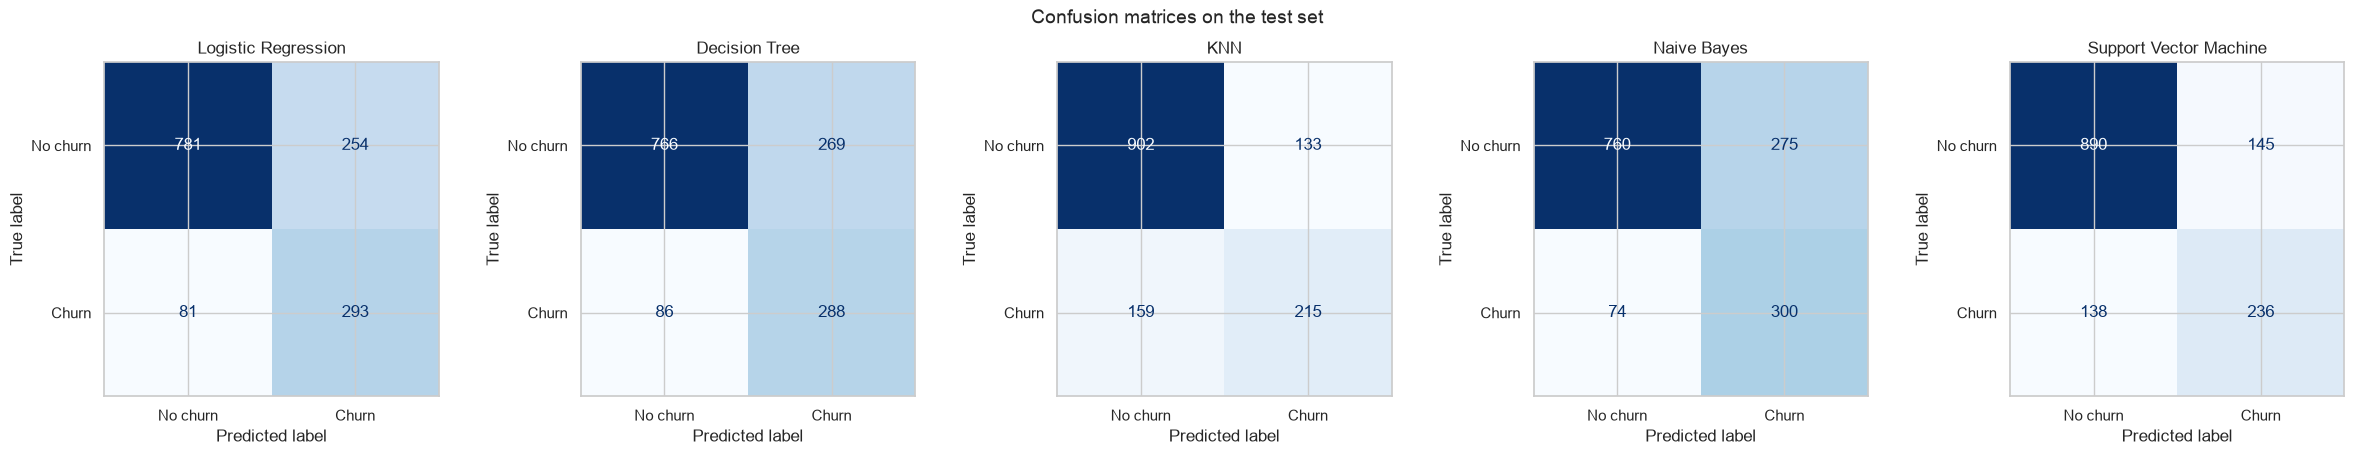

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, (name, (y_pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.suptitle("Confusion matrices on the test set", fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
for name, (y_pred, _) in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], digits=4))

=== Logistic Regression ===
              precision    recall  f1-score   support

    No churn     0.9060    0.7546    0.8234      1035
       Churn     0.5356    0.7834    0.6363       374

    accuracy                         0.7622      1409
   macro avg     0.7208    0.7690    0.7298      1409
weighted avg     0.8077    0.7622    0.7737      1409

=== Decision Tree ===
              precision    recall  f1-score   support

    No churn     0.8991    0.7401    0.8119      1035
       Churn     0.5171    0.7701    0.6187       374

    accuracy                         0.7480      1409
   macro avg     0.7081    0.7551    0.7153      1409
weighted avg     0.7977    0.7480    0.7606      1409

=== KNN ===
              precision    recall  f1-score   support

    No churn     0.8501    0.8715    0.8607      1035
       Churn     0.6178    0.5749    0.5956       374

    accuracy                         0.7928      1409
   macro avg     0.7340    0.7232    0.7281      1409
weighted avg

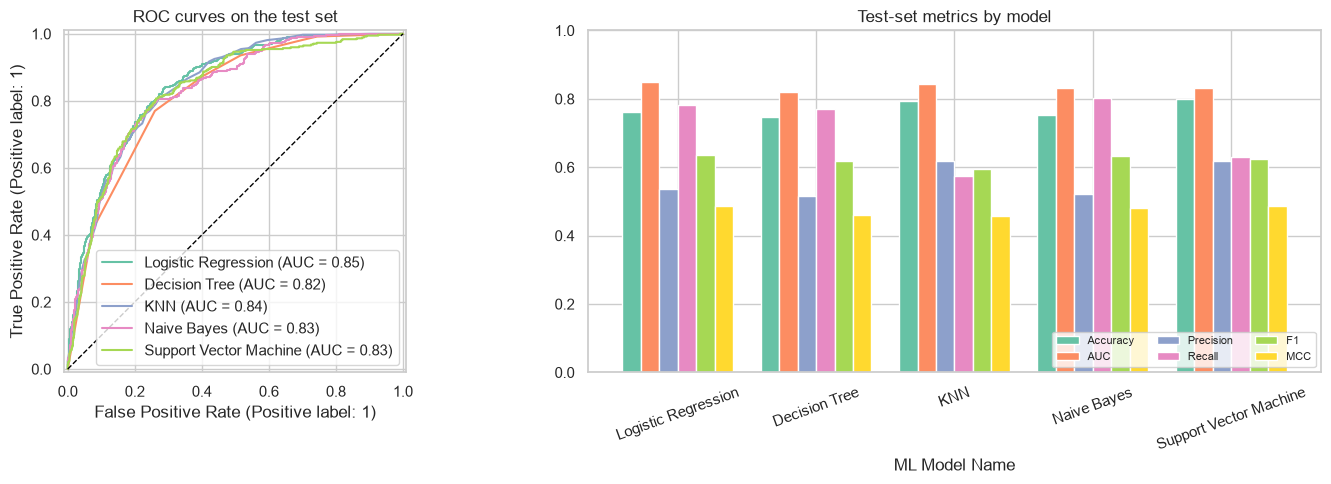

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, (_, y_score) in preds.items():
    RocCurveDisplay.from_predictions(y_test, y_score, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves on the test set")

results[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_ylim(0, 1)
axes[1].set_title("Test-set metrics by model")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(loc="lower right", ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
gap = pd.DataFrame({"CV F1 (train folds)": tuned_cv["f1"], "Test F1": results["F1"]})
gap["difference"] = (gap["Test F1"] - gap["CV F1 (train folds)"]).round(4)
gap

,CV F1 (train folds),Test F1,difference
Logistic Regression,0.6302,0.6363,0.0061
Decision Tree,0.6204,0.6187,-0.0017
KNN,0.6048,0.5956,-0.0092
Naive Bayes,0.6075,0.6322,0.0247
Support Vector Machine,0.6225,0.6252,0.0027


**Generalisation check:** the test-set F1 of every model is close to its cross-validated F1, so the tuned models are not overfitting and the CV estimates were reliable.

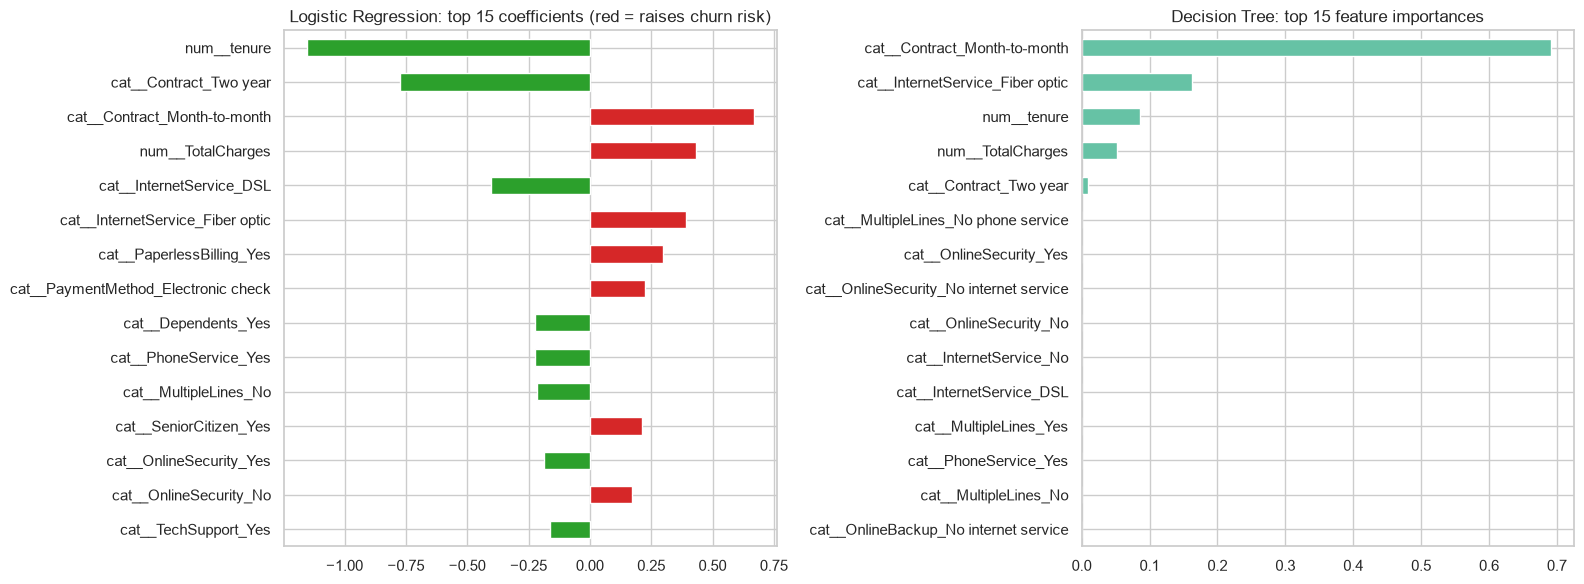

In [25]:
lr_model = final_models["Logistic Regression"]
coefs = pd.Series(lr_model.named_steps["clf"].coef_[0], index=lr_model.named_steps["prep"].get_feature_names_out())
dt_model = final_models["Decision Tree"]
imps = pd.Series(dt_model.named_steps["clf"].feature_importances_, index=dt_model.named_steps["prep"].get_feature_names_out())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:15][::-1]
top.plot(kind="barh", ax=axes[0], color=np.where(top > 0, "#d62728", "#2ca02c"))
axes[0].set_title("Logistic Regression: top 15 coefficients (red = raises churn risk)")
imps.sort_values()[-15:].plot(kind="barh", ax=axes[1])
axes[1].set_title("Decision Tree: top 15 feature importances")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.tree import export_text
print(export_text(dt_model.named_steps["clf"], feature_names=list(dt_model.named_steps["prep"].get_feature_names_out())))

|--- cat__Contract_Month-to-month <= 0.50
|   |--- cat__InternetService_Fiber optic <= 0.50
|   |   |--- cat__Contract_Two year <= 0.50
|   |   |   |--- class: 0
|   |   |--- cat__Contract_Two year >  0.50
|   |   |   |--- class: 0
|   |--- cat__InternetService_Fiber optic >  0.50
|   |   |--- num__tenure <= 1.57
|   |   |   |--- class: 0
|   |   |--- num__tenure >  1.57
|   |   |   |--- class: 0
|--- cat__Contract_Month-to-month >  0.50
|   |--- cat__InternetService_Fiber optic <= 0.50
|   |   |--- num__tenure <= -1.09
|   |   |   |--- class: 1
|   |   |--- num__tenure >  -1.09
|   |   |   |--- class: 0
|   |--- cat__InternetService_Fiber optic >  0.50
|   |   |--- num__TotalCharges <= -0.31
|   |   |   |--- class: 1
|   |   |--- num__TotalCharges >  -0.31
|   |   |   |--- class: 1



**Model interpretation:** the depth-3 tree splits first on month-to-month contract, then on fiber-optic internet, then on tenure — exactly the three strongest signals found in the EDA. Both the linear and the tree model rely on the same drivers found in the EDA — **contract type, tenure, internet service (fiber optic), charges, electronic-check payment and the absence of security/tech-support add-ons**. The models agree with the business intuition, which increases confidence in the results.

Note on `TotalCharges`: in the EDA, churners had *lower* total charges, yet its logistic coefficient is *positive*. This is the multicollinearity effect flagged in section 4.4: once `tenure` (the largest negative coefficient) is in the model, a higher `TotalCharges` at the same tenure means a higher price paid, which raises churn risk. Individual coefficients of correlated features should therefore not be read in isolation; the model's predictions are unaffected.

## 10. Observations on each model

In [27]:
best = results["F1"].idxmax()
print("Best by F1 :", best, results.loc[best, "F1"])
print("Best by MCC:", results["MCC"].idxmax(), results["MCC"].max())
print("Best by AUC:", results["AUC"].idxmax(), results["AUC"].max())
print("Best by Accuracy:", results["Accuracy"].idxmax(), results["Accuracy"].max())

Best by F1 : Logistic Regression 0.6363
Best by MCC: Support Vector Machine 0.488
Best by AUC: Logistic Regression 0.8486
Best by Accuracy: Support Vector Machine 0.7991


### Comparison table (held-out test set, 1,409 customers)

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.7622 | **0.8486** | 0.5356 | 0.7834 | **0.6363** | 0.4875 |
| Decision Tree | 0.7480 | 0.8202 | 0.5171 | 0.7701 | 0.6187 | 0.4607 |
| KNN | 0.7928 | 0.8429 | 0.6178 | 0.5749 | 0.5956 | 0.4570 |
| Naive Bayes | 0.7523 | 0.8327 | 0.5217 | **0.8021** | 0.6322 | 0.4820 |
| Support Vector Machine | **0.7991** | 0.8324 | **0.6194** | 0.6310 | 0.6252 | **0.4880** |

### Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Best **AUC (0.849)** and **F1 (0.636)**, and an MCC (0.4875) that is practically tied with the best. With `class_weight="balanced"` and mild L2 regularisation (C = 0.3) it catches 78 % of churners. Its strong result shows that, after one-hot encoding, churn risk is close to **linearly separable** (contract, tenure, fiber, e-check and missing add-ons each add risk). It was also the best model in cross-validation (CV F1 0.630), is stable across C, fast, and its coefficients are directly interpretable. |
| **Decision Tree** | Untuned, the tree overfit badly (CV F1 ≈ 0.50, AUC ≈ 0.66). Restricting it to **depth 3** with balanced weights lifts test F1 to 0.619 and recall to 0.77, but it has the **lowest AUC (0.820)** and a low MCC: a depth-3 tree has only 8 leaves, so it produces a few distinct probability values and ranks customers coarsely. Its advantage is a very readable rule set: it flags *month-to-month customers on fiber optic* and *new month-to-month customers* as churners (contract → fiber optic → tenure). |
| **KNN** | Good accuracy (0.793) and precision (0.618) but the **lowest recall (0.575)**, F1 and MCC. KNN cannot use class weights, so with 73 % non-churners in every neighbourhood it predicts "No" more often and misses about 4 in 10 churners. Its accuracy mostly comes from getting the majority class right, which shows why accuracy is not a good selection metric here. It needs a large k (61) to be stable and is the slowest model at prediction time (it compares each customer with all 5,634 training rows). |
| **Naive Bayes** | Highest **recall (0.802)** and a strong F1 (0.632) / MCC (0.482), even though its independence assumption is clearly violated (`TotalCharges` ≈ `tenure × MonthlyCharges`; six columns share the "No internet service" level). Heavy `var_smoothing` (1.0) was needed to control the resulting over-confidence. Its test F1 is 0.025 above its CV F1, so part of this good test result is luck of the split; in cross-validation it ranks below LR and SVM. It is the cheapest model to train. |
| **Support Vector Machine** | RBF-SVM (C = 0.3, γ = 0.1, balanced) has the best **accuracy (0.799)**, **precision (0.619)** and **MCC (0.488)**, with a moderate recall (0.631). Its labels come from Platt-calibrated probabilities ≥ 0.5; calibration pulls probabilities back toward the true 26.5 % churn rate, which partly undoes the class weighting, so it is more conservative than LR (fewer false alarms, more missed churners). Its AUC (0.832) is lower than LR's, so the RBF kernel does **not** rank customers better than the linear model — the boundary is close to linear. It is also the most expensive model to train and needs the extra calibration step. |
| **Overall winner** | **Logistic Regression.** It has the best AUC and F1, its MCC is equal to the SVM's (difference 0.0005), and it was the best model in cross-validation. For a retention campaign, its higher recall (78 % vs 63 % of churners found) is worth the lower precision, and it is the simplest, fastest and most explainable model. The SVM is the runner-up and the better choice if false alarms are expensive; KNN is the weakest on the imbalance-aware metrics. |

## 11. Save the models and artifacts
Each file in `model/` is a **complete pipeline** (imputer + scaler + one-hot encoder + classifier). The Streamlit app only has to load the file and call `predict` / `predict_proba` on the cleaned uploaded CSV — **no retraining** happens in the app. The test metrics and the chosen hyper-parameters are stored in `model/metrics.json` for reference.

In [28]:
for name, model in final_models.items():
    joblib.dump(model, MODEL_DIR / MODEL_FILES[name], compress=3)

meta = {
    "dataset": "Telco Customer Churn (Kaggle: blastchar/telco-customer-churn)",
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "selection_metric": "f1",
    "best_params": {n: {k.replace("clf__", ""): (v if isinstance(v, (str, int, float, type(None))) else float(v))
                        for k, v in gs.best_params_.items()} for n, gs in searches.items()},
    "test_metrics": {n: {k: round(float(v), 4) for k, v in m.items()} for n, m in test_rows.items()},
}
(MODEL_DIR / "metrics.json").write_text(json.dumps(meta, indent=2))
sorted(p.name for p in MODEL_DIR.iterdir())

['decision_tree.joblib',
 'knn.joblib',
 'logistic_regression.joblib',
 'metrics.json',
 'naive_bayes.joblib',
 'svm.joblib']

### Sanity check: reload the saved files and score `test_data.csv`
This replicates exactly what the Streamlit app does and confirms that the saved models reproduce the metrics above.

In [29]:
check_df = pd.read_csv("test_data.csv")
Xc, yc = clean_features(check_df), encode_target(check_df[TARGET_COL])
reloaded = {}
for name, fname in MODEL_FILES.items():
    m = joblib.load(MODEL_DIR / fname)
    reloaded[name] = compute_metrics(yc, predict_at_threshold(m, Xc, 0.5), positive_scores(m, Xc))
reloaded = pd.DataFrame(reloaded).T.round(4)
assert np.allclose(reloaded.values, results.values), "Reloaded models do not reproduce the metrics"
print("Saved models reproduce the test metrics exactly.")
reloaded

Saved models reproduce the test metrics exactly.


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.7622,0.8486,0.5356,0.7834,0.6363,0.4875
Decision Tree,0.7480,0.8202,0.5171,0.7701,0.6187,0.4607
KNN,0.7928,0.8429,0.6178,0.5749,0.5956,0.4570
Naive Bayes,0.7523,0.8327,0.5217,0.8021,0.6322,0.4820
Support Vector Machine,0.7991,0.8324,0.6194,0.6310,0.6252,0.4880
